C:\Users\Harini.S\AppData\Local\Temp\ipykernel_488\1041450450.py:7: DtypeWarning: Columns (0: Unnamed: 22) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("archive/cleaned_amazon_sales.csv")


Monthly Sales with Growth Percentage:
  Year_Month       Amount      Growth_%
0    2022-03    107128.85           NaN
1    2022-04  30653103.32  28513.303811
2    2022-05  27741396.75     -9.498897
3    2022-06  24807024.38    -10.577594

Best Performing Month:
Year_Month         2022-04
Amount         30653103.32
Growth_%      28513.303811
Name: 1, dtype: object

Worst Performing Month:
Year_Month      2022-03
Amount        107128.85
Growth_%            NaN
Name: 0, dtype: object


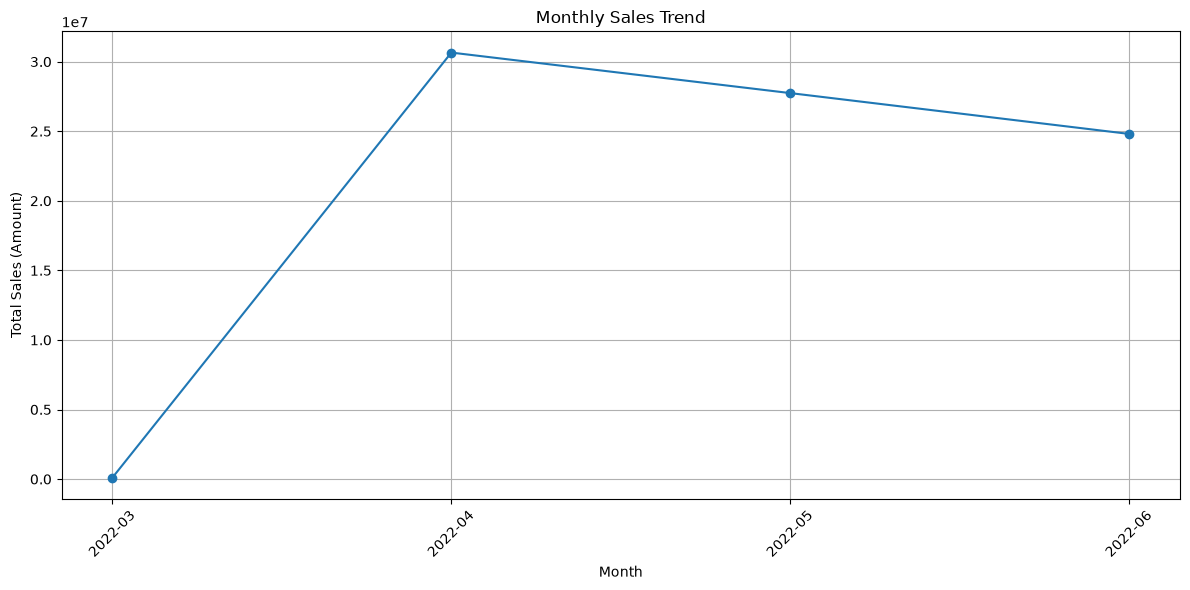

In [ ]:
#Task 3: Data Analysis & Visualization

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("archive/cleaned_amazon_sales.csv")

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

df["Year_Month"] = df["Date"].dt.to_period("M")

monthly_sales = df.groupby("Year_Month")["Amount"].sum().reset_index()

monthly_sales["Growth_%"] = monthly_sales["Amount"].pct_change() * 100

print("Monthly Sales with Growth Percentage:")
print(monthly_sales)

best_month = monthly_sales.loc[monthly_sales["Amount"].idxmax()]

print("\nBest Performing Month:")
print(best_month)

worst_month = monthly_sales.loc[monthly_sales["Amount"].idxmin()]

print("\nWorst Performing Month:")
print(worst_month)

# Plot monthly sales trend
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales["Year_Month"].astype(str),
    monthly_sales["Amount"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales (Amount)")
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()